# Billboard: Top 10 or Not?

**BA780 Team Assignment — Team A05**

Team members: Omar Tawfik, Caitlin Jeng, Muhammad Azaan, Xiaoquan Dai

---

### Research question

Among songs that reached the Billboard Hot 100 between January 2018 and September 2026,
what distinguishes those that climbed into the **Top 10** from those that peaked lower?

### Data sources, access and licensing

| Source | What we used | Access URL | Licence |
|---|---|---|---|
| Billboard Hot 100 weekly archive (mhollingshead) | every weekly chart, 1958-2026 | https://github.com/mhollingshead/billboard-hot-100 | **No licence declared by the repository.** The chart itself is Billboard's copyrighted compilation |
| LRCLIB | song lyrics | https://lrclib.net/docs | **No licence stated on the public docs page.** Lyrics belong to their rights holders |
| MusicBrainz | release dates, genres, artist data | https://musicbrainz.org/doc/MusicBrainz_API | Core data **CC0 / public domain** |

Only MusicBrainz states its licence. We use the other two for non-commercial academic
analysis only and do not redistribute the lyrics or the chart archive.

### How to run this notebook

- **Billboard:** read from `data/raw/all.json` if it exists, otherwise downloaded from
  GitHub (44 MB). Either way we keep charts up to **2026-09-19**, so the results do not
  change when new weeks are added.
- **Lyrics and MusicBrainz:** in Colab, upload `raw_api_data.zip` (4 MB) when asked.
  Locally the files are read from `data/raw/`. The notebook makes no API calls; the
  collection scripts in `scripts/` fetched these files once.
- Runs top to bottom with `np.random.seed(42)`.

In [1]:
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats      # used only for the two significance tests in Section 4

np.random.seed(42)

## Executive summary

We built a dataset of 5,342 songs that entered the Billboard Hot 100 between January 2018
and September 2026 by joining the weekly chart archive to lyrics from LRCLIB (99.4% matched)
and release data from MusicBrainz (99.0% matched); 519 of them (9.7%) reached the Top 10.
The strongest signals are about the artist and the release, not the song: artists with ten
or more earlier Top 10 hits reach the Top 10 at 18.5%, against 5.8% for artists with none,
and a song released in the same week as four to eight other songs by the same artist
reaches it at only 2.1%. Lyric style barely separates hits from the rest: of four measures
only vocabulary diversity differs, and only slightly. Two apparent findings did not survive
testing: debut position looked perfectly predictive only because a song that debuts inside
the Top 10 already meets the definition of the target, and the month effect is no longer
significant once big album drops are removed (p = 0.009 becomes p = 0.906). We therefore
treat the artist's track record and the release strategy as the main predictors, and
lyric-style features as weak.

**So what:** who released the song, and how, matters more than what the song says.

## 1. Problem definition

**Business framing.** A label deciding where to spend marketing money wants to know which
songs have a realistic chance of a Top 10 placing, and which levers actually change that
chance. "Make a better song" is not actionable; "release this as a single rather than as
track nine of an album" is.

**Analytical framing.**

- **Unit of analysis:** one song, identified by its title and the artist credit it debuted under.
- **Target:** `top10`, whether the song ever reached positions 1-10.
- **Population:** songs whose *first* week on the chart is on or after 2018-01-01, so every
  song is observed from the start of its run.
- **Predictors:** only what was known in the song's debut week: the artist's earlier chart
  record, genre, lyrics, release date, and how many songs the artist released that week.

**The rule that shapes the cleaning.** Every predictor must be knowable at debut. An
artist's history only counts songs that debuted *strictly earlier*, and lyrics come from
the credit the song debuted under, so a verse added later by a featured artist cannot leak
back in. Question 10 shows what happens when this rule is broken.

**Two exclusions.** Songs still on the chart have no final peak, so they are dropped from
every test. Songs from 2025-2026 are held back as a test set: all hypothesis tests below
use the 2018-2024 training years only.

**So what:** we are explaining a 1-in-10 event using only what a label could know in release week.

## 2. Data description

| File | One row per | Rows | Key columns we use |
|---|---|---|---|
| `all.json` (Billboard) | song per chart week | 355,487 rows in 3,555 weekly charts, 1958-2026 | date, song, artist, position |
| `lyrics.csv` (LRCLIB) | chart credit | 5,377 | lyrics text, instrumental flag, duration, match score |
| `mb_songs.csv` (MusicBrainz) | chart credit | 5,349 | release date, recording length, genres and vote counts, artist ids, match score |
| `mb_artists.csv` (MusicBrainz) | artist | 1,269 | genres and vote counts |

We keep the whole archive back to 1958, even though the study starts in 2018, because an
artist's earlier record must be counted from all of chart history: Drake's count of
earlier hits would be wrong if we only looked back to 2018.

LRCLIB and MusicBrainz were matched to Billboard songs by name, so each match has a
confidence score from 0 to 100. We treat 72 or more as a trusted match.

**So what:** one chart archive is the backbone; lyrics and MusicBrainz add information about each song.

## 3. Data cleaning

All cleaning happens in this section, starting from the raw files. Each step prints a
before/after count so the effect of every change is visible.

### Step 1. Load and inspect

In Colab, the first cell asks for one upload, `raw_api_data.zip`, and unzips it into
`data/raw/`. Locally the CSV files are already there.

In [2]:
# In Colab, upload raw_api_data.zip once. Locally, the three CSV files are already in data/raw/.
if not os.path.exists('data/raw/lyrics.csv'):
    from google.colab import files
    files.upload()                                     # choose raw_api_data.zip
    with zipfile.ZipFile('raw_api_data.zip') as upload:
        upload.extractall('data/raw')

print(os.listdir('data/raw'))

['mb_songs.csv', 'mb_artists.csv', 'lyrics.csv', 'all.json']


The Billboard archive is one JSON file with a row per week; each week holds a list of 100
songs. We read the local copy if there is one, otherwise the file on GitHub.

In [3]:
BILLBOARD_URL = 'https://raw.githubusercontent.com/mhollingshead/billboard-hot-100/main/all.json'
LAST_CHART = '2026-09-19'   # the last week we analysed; charts added later are ignored

if os.path.exists('data/raw/all.json'):
    charts = pd.read_json('data/raw/all.json')
else:
    charts = pd.read_json(BILLBOARD_URL)

print(len(charts), 'weekly charts downloaded')
charts.head(3)

3555 weekly charts downloaded


,date,data
0,1958-08-04,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
1,1958-08-11,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
2,1958-08-18,"[{'song': 'Nel Blu Dipinto Di Blu (Volare)', '..."


Each week's list is turned into one row per song per week with a simple `for` loop. Then
we convert the date column to a real date and keep only charts up to 2026-09-19.

In [4]:
rows = []
for i in range(len(charts)):
    for entry in charts['data'][i]:
        rows.append([charts['date'][i], entry['song'], entry['artist'], entry['this_week']])

weekly = pd.DataFrame(rows, columns=['chart_date', 'title', 'artist', 'position'])
weekly['chart_date'] = pd.to_datetime(weekly['chart_date'])
weekly = weekly[weekly['chart_date'] <= LAST_CHART]

print('weekly charts kept:', len(weekly['chart_date'].unique()))
print('chart rows:', len(weekly))
weekly.head()

weekly charts kept: 3555
chart rows: 355487


,chart_date,title,artist,position
0,1958-08-04,Poor Little Fool,Ricky Nelson,1
1,1958-08-04,Patricia,Perez Prado And His Orchestra,2
2,1958-08-04,Splish Splash,Bobby Darin,3
3,1958-08-04,Hard Headed Woman,Elvis Presley With The Jordanaires,4
4,1958-08-04,When,Kalin Twins,5


No missing values and no fully duplicated rows. The 13 rows where the same title and artist
appear twice in one week are real: in 1990 two different recordings of "Unchained Melody"
by The Righteous Brothers were on the chart at the same time. They are from before 2018
and only affect that act's own history, so we leave them.

In [5]:
weekly.info()
print()
print('missing values:')
print(weekly.isna().sum())
print()
print('duplicate rows:', weekly.duplicated().sum())
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

<class 'pandas.DataFrame'>
RangeIndex: 355487 entries, 0 to 355486
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   chart_date  355487 non-null  datetime64[us]
 1   title       355487 non-null  str           
 2   artist      355487 non-null  str           
 3   position    355487 non-null  int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 10.8 MB

missing values:
chart_date    0
title         0
artist        0
position      0
dtype: int64

duplicate rows: 0


same song twice in one week: 13


Now the three files of API results. We keep only the columns we use.

In [6]:
lyrics = pd.read_csv('data/raw/lyrics.csv')
lyrics = lyrics[['title', 'artist', 'plain_lyrics', 'instrumental', 'duration', 'match_score']]

mb_songs = pd.read_csv('data/raw/mb_songs.csv')
mb_songs = mb_songs[['title', 'artist', 'first_release_date', 'recording_length_ms',
                     'genres', 'genre_counts', 'artist_mbids', 'match_score']]

mb_artists = pd.read_csv('data/raw/mb_artists.csv')
mb_artists = mb_artists[['artist_mbid', 'genres', 'genre_counts']]

print('lyrics:', lyrics.shape, '| mb_songs:', mb_songs.shape, '| mb_artists:', mb_artists.shape)

lyrics: (5377, 6) | mb_songs: (5349, 8) | mb_artists: (1269, 3)


Missing values here are expected: 33 songs have no lyrics text (no match, or an
instrumental), and 1,605 MusicBrainz recordings have no genre. Each file has exactly one
row per key, so the joins in Step 7 can be checked with `validate='one_to_one'`.

In [7]:
print('lyrics, missing values:')
print(lyrics.isna().sum())
print()
print('MusicBrainz songs, missing values:')
print(mb_songs.isna().sum())
print()
print('duplicate keys:', lyrics.duplicated(subset=['title', 'artist']).sum(),
      mb_songs.duplicated(subset=['title', 'artist']).sum(),
      mb_artists.duplicated(subset=['artist_mbid']).sum())

lyrics, missing values:
title             0
artist            0
plain_lyrics     33
instrumental     32
duration        283
match_score       0
dtype: int64

MusicBrainz songs, missing values:
title                     0
artist                    0
first_release_date       17
recording_length_ms    3033
genres                 1605
genre_counts           1605
artist_mbids             56
match_score               0
dtype: int64

duplicate keys: 0 0 0


### Step 2. Weekly rows → one row per chart credit

The archive repeats a song every week it is on the chart. We collapse it to one row per
title and artist credit: first and last week, best (lowest) position, debut position and
number of weeks. We write this as a function because Step 3 repeats it.

In [8]:
def one_row_per_song(weekly):
    """Collapse the weekly chart rows into one row per (title, artist)."""
    weekly = weekly.sort_values('chart_date')
    songs = weekly.groupby(['title', 'artist']).agg(
        debut_date=('chart_date', 'min'),
        last_date=('chart_date', 'max'),
        peak_position=('position', 'min'),
        debut_position=('position', 'first'),
        weeks_on_chart=('chart_date', 'count'),
    ).reset_index()
    songs['top10'] = songs['peak_position'] <= 10
    return songs

In [9]:
credits = one_row_per_song(weekly)
credits_2018 = credits[credits['debut_date'] >= '2018-01-01']

print('chart rows:', len(weekly), '-> chart credits:', len(credits))
print('credits that debuted in 2018 or later:', len(credits_2018))
print('of those, reached the Top 10:', credits_2018['top10'].sum())
credits.head()

chart rows: 355487 -> chart credits: 32723
credits that debuted in 2018 or later: 5377
of those, reached the Top 10: 521


,title,artist,debut_date,last_date,peak_position,debut_position,weeks_on_chart,top10
0,"""B"" Girls",Young And Restless,1990-05-05,1990-08-11,54,84,15,False
1,"""Cherry Cherry"" from Hot August Night",Neil Diamond,1973-03-17,1973-05-19,31,84,10,False
2,"""Having A Party"" Medley",The Ovations (Featuring Louis Williams),1973-10-13,1973-12-08,56,99,9,False
3,"""Joy"" Pt. I",Isaac Hayes,1973-12-22,1974-02-16,30,72,9,False
4,"""Roots"" Medley",Quincy Jones,1977-03-05,1977-04-16,57,86,7,False


### Step 3. Merge songs that Billboard listed under two credits

Sometimes Billboard changes a song's credit while it is on the chart ("Kanye West" became
"Ye"; a featured artist is added). The song then appears as two rows, which splits its
weeks and understates its peak. Our team reviewed every candidate pair by hand and kept
**34 songs** to merge. They are written out below as a plain list: each line renames a
later credit to the credit the song **debuted** under.

We rejected pairs that only looked alike: songs that were on the chart in the same week,
and different recordings such as "White Christmas (1947)" and V & Bing Crosby's version.

In [10]:
DUPLICATE_CREDITS = [
    ['360', 'Charli xcx',
     '360', 'Charli XCX'],
    ['Act II: Date @ 8', '4Batz Featuring Drake',
     'Act II: Date @ 8', '4Batz'],
    ['Ahi', 'Karol G With Drake',
     'Ahi', 'Karol G & Drake'],
    ['Apple', 'Charli xcx',
     'Apple', 'Charli XCX'],
    ['BbY WOW', 'Karol G With Judeline & rusowsky',
     'BbY WOW', 'Karol G, Judeline & rusowsky'],
    ['Blue Strips', 'jessie murph',
     'Blue Strips', 'Jessie Murph'],
    ['Bottle Rockets', 'Scotty McCreery & Hootie & the Blowfish',
     'Bottle Rockets', 'Scotty McCreery & Hootie & The Blowfish'],
    ['Burn', '¥$: Ye & Ty Dolla $ign',
     'Burn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Burning Blue', 'Mariah the Scientist',
     'Burning Blue', 'Mariah The Scientist'],
    ['Carnival', '¥$: Ye & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti',
     'Carnival', '¥$: Kanye West & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti'],
    ['Dial Drunk', 'Noah Kahan With Post Malone',
     'Dial Drunk', 'Noah Kahan'],
    ['Dracula', 'Tame Impala & JENNIE',
     'Dracula', 'Tame Impala'],
    ['Ever Since U Left Me (I Went Deaf)', 'French Montana & Max B',
     'Ever Since U Left Me', 'Max B & French Montana'],
    ['Fuk Sumn', '¥$: Ye & Ty Dolla $ign',
     'Fuk Sumn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Get In With Me', 'BossMan DLow',
     'Get In With Me', 'BossMan Dlow'],
    ['Go Away', 'Weezer Featuring Best Coast',
     'Go Away', 'Weezer'],
    ['Golden', 'HUNTR/X: EJAE, Audrey Nuna & REI AMI',
     'Golden', 'HUNTR/X, EJAE, Audrey Nuna & Rei Ami'],
    ['Hard Fought Hallelujah', 'Brandon Lake X Jelly Roll',
     'Hard Fought Hallelujah', 'Brandon Lake'],
    ['Hell At Night', 'BigXthaPlug Featuring Ella Langley',
     'Hell At Night', 'BigXthaPlug & Ella Langley'],
    ["I Ain't Coming Back", 'Morgan Wallen Featuring Post Malone',
     "I Ain't Coming Back", 'Morgan Wallen & Post Malone'],
    ['Is It A Crime', 'Mariah The Scientist & Kali Uchis',
     'Is It A Crime', 'Mariah the Scientist & Kali Uchis'],
    ['Jingle Bells', 'Frank Sinatra With Orchestra Conducted By Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Jingle Bells', 'Frank Sinatra With The Orchestra & Chorus Of Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Karma', 'Taylor Swift Featuring Ice Spice',
     'Karma', 'Taylor Swift'],
    ["Let's Go", 'Key Glock & Young Dolph',
     "Let's Go", 'Key Glock'],
    ['One More Time', 'blink-182',
     'One More Time', 'Blink-182'],
    ['One Of The Girls', 'The Weeknd, Jennie & Lily Rose Depp',
     'One Of The Girls', 'The Weeknd, JENNIE & Lily Rose Depp'],
    ['Shake Dat Ass (Twerk Song)', 'BossMan Dlow',
     'Shake Dat Ass (Twerk Song)', 'BossMan DLow'],
    ['Soak City', '310babii',
     'Soak City (Do It)', '310babii'],
    ['Still', 'Karol G With Bruno Mars',
     'Still', 'Karol G & Bruno Mars'],
    ['Sugar On My Tongue', 'Tyler, The Creator',
     'Sugar On My Tongue', 'Tyler, the Creator'],
    ['Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YKNIECE',
     'Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YK NIECE'],
    ['Tweaker', 'GELO',
     'Tweaker', 'Gelo'],
    ['Typa', 'Glorilla',
     'Typa', 'GloRilla'],
    ['Your Idol', 'Saja Boys: Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee',
     'Your Idol', 'Saja Boys, Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee'],
]

Apply the renames to the weekly rows, then rebuild the song table. Two songs, "Carnival" and
"Karma", had been counted as two separate Top 10 hits, so the Top 10 count drops by two.

In [11]:
for old_title, old_artist, new_title, new_artist in DUPLICATE_CREDITS:
    match = (weekly['title'] == old_title) & (weekly['artist'] == old_artist)
    weekly.loc[match, 'title'] = new_title
    weekly.loc[match, 'artist'] = new_artist

songs = one_row_per_song(weekly)
songs_2018 = songs[songs['debut_date'] >= '2018-01-01']

print('songs from 2018 on:', len(credits_2018), '->', len(songs_2018))
print('Top 10 songs from 2018 on:', credits_2018['top10'].sum(), '->', songs_2018['top10'].sum())
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

songs from 2018 on: 5377 -> 5342
Top 10 songs from 2018 on: 521 -> 519
same song twice in one week: 13


For example, "Carnival" now has one row with its full chart run and its best position.

In [12]:
check = songs_2018[songs_2018['title'].isin(['Carnival', 'Karma', 'Golden'])]
check[['title', 'artist', 'debut_date', 'peak_position', 'weeks_on_chart']]

,title,artist,debut_date,peak_position,weeks_on_chart
4325,Carnival,¥$: Kanye West & Ty Dolla $ign Featuring Rich ...,2024-02-24,1,19
9570,Golden,"HUNTR/X, EJAE, Audrey Nuna & Rei Ami",2025-07-05,1,47
9571,Golden,Harry Styles,2019-12-28,57,20
15096,Karma,Queen Naija,2018-07-14,63,2
15097,Karma,Rod Wave,2024-10-26,100,1
15098,Karma,Taylor Swift,2022-11-05,2,30


### Step 4. Split each credit into individual artists

"Bruno Mars & Cardi B" is two artists. To count each artist's history, we lowercase the
credit, replace every separator Billboard uses with `|`, and split on `|`. A few names
contain a separator but are one act; we protect those by rewriting them first.

We tested every protected name from an earlier, longer list: only these three change any
2018+ song's results, so the list stays this short.

In [13]:
# Names that contain a separator but are one act. Each is rewritten so the split leaves it whole.
PROTECTED_NAMES = {
    'lil nas x': 'lil nas-x',          # " x " would cut "Lil Nas X & Jack Harlow" in the wrong place
    'sam & dave': 'sam and dave',      # keeps the 1960s duo out of the UK rapper Dave's history
    'sonny & cher': 'sonny and cher',  # keeps the duo's hits out of Cher's solo history
}

# Words Billboard uses between artists, including its own typos ("Feauring").
# Longer phrases come first so " a duet with " is removed before " with ".
SEPARATORS = [' a duet with ', ' duet with ', ' featuring ', ' feauring ', ' featauring ',
              ' feat. ', ' feat ', ' ft. ', ' with ', ' w/ ', ' vs. ', ' vs ',
              ' introducing ', ' presents ', ' x ', ' & ', ', ', ': ', ' (']

In [14]:
names = songs['artist'].str.lower()
names = names.str.replace('"', '', regex=False).str.replace(')', '', regex=False)
for name, safe_name in PROTECTED_NAMES.items():
    names = names.str.replace(name, safe_name, regex=False)
for separator in SEPARATORS:
    names = names.str.replace(separator, '|', regex=False)

artist_columns = names.str.split('|', expand=True)
songs['primary_artist'] = artist_columns[0].str.strip()
songs['has_feature'] = songs['artist'].str.lower().str.contains(r'featuring|feauring|featauring|feat\.|ft\.')

print('most artists in one credit:', artist_columns.shape[1])

most artists in one credit: 10


Some examples. The first column is the lead (primary) artist. "¥$" keeps its members as
separate artists, so Kanye West's history still counts on ¥$ songs.

In [15]:
examples = ['Bruno Mars & Cardi B', 'Lil Nas X & Jack Harlow', '¥$: Ye & Ty Dolla $ign',
            'Silk Sonic (Bruno Mars & Anderson .Paak)', 'Iggy Azalea Feauring Tyga']
is_example = songs['artist'].isin(examples)
pd.concat([songs.loc[is_example, ['artist']], artist_columns[is_example]], axis=1).drop_duplicates('artist')

,artist,0,1,2,3,4,5,6,7,8,9
3201,Silk Sonic (Bruno Mars & Anderson .Paak),silk sonic,bruno mars,anderson .paak,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8181,Bruno Mars & Cardi B,bruno mars,cardi b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14065,Lil Nas X & Jack Harlow,lil nas-x,jack harlow,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15397,Iggy Azalea Feauring Tyga,iggy azalea,tyga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 5. Each artist's chart history before the song debuted

First we stack the split columns into one row per (song, artist). A song credited to
"Bruno Mars & Cardi B" appears once under each artist.

In [16]:
# One row per (song, credited artist): stack the split columns on top of each other.
pieces = []
for column in artist_columns.columns:
    piece = songs[['title', 'artist', 'debut_date', 'top10']].copy()
    piece['artist_name'] = artist_columns[column].str.strip()
    pieces.append(piece)

artist_songs = pd.concat(pieces)
artist_songs = artist_songs.dropna(subset=['artist_name'])
artist_songs = artist_songs[artist_songs['artist_name'] != '']
artist_songs = artist_songs.drop_duplicates(subset=['title', 'artist', 'artist_name'])

print('songs:', len(songs), '-> song-artist rows:', len(artist_songs))

songs: 32688 -> song-artist rows: 39939


Then we merge every 2018+ song with all songs by its lead artist, keep only the songs that
debuted **strictly earlier**, and count them. Songs released in the same week do not
count as "earlier", so nothing from the song's own debut leaks in.

In [17]:
earlier_songs = artist_songs.rename(columns={
    'title': 'earlier_title', 'artist': 'earlier_artist',
    'debut_date': 'earlier_debut', 'top10': 'earlier_top10', 'artist_name': 'primary_artist'})

recent = songs[songs['debut_date'] >= '2018-01-01']
pairs = pd.merge(recent[['title', 'artist', 'debut_date', 'primary_artist']],
                 earlier_songs, on='primary_artist', how='left')
earlier = pairs[pairs['earlier_debut'] < pairs['debut_date']]

history = earlier.groupby(['title', 'artist']).agg(
    prior_entries=('earlier_title', 'count'),
    prior_top10s=('earlier_top10', 'sum'),
).reset_index()
print('recent songs:', len(recent), '| (song, earlier song) pairs:', len(earlier),
      '| songs with any history:', len(history))

recent songs: 5342 | (song, earlier song) pairs: 241042 | songs with any history: 4831


Two leakage checks. A song must never count itself, and a slow recount of 200 random songs,
done one at a time, must give the same numbers.

In [18]:
# Check 1: no song is ever counted in its own history.
self_counted = (earlier['earlier_title'] == earlier['title']) & (earlier['earlier_artist'] == earlier['artist'])
print('songs counted in their own history:', self_counted.sum())

# Check 2: recount 200 random songs the slow way and compare.
sample = recent.sample(200, random_state=42)
mismatches = 0
for i in sample.index:
    same_artist = artist_songs[artist_songs['artist_name'] == sample.loc[i, 'primary_artist']]
    before = same_artist[same_artist['debut_date'] < sample.loc[i, 'debut_date']]
    found = history[(history['title'] == sample.loc[i, 'title']) & (history['artist'] == sample.loc[i, 'artist'])]
    if before['top10'].sum() != found['prior_top10s'].sum():
        mismatches = mismatches + 1
print('mismatches in 200 recounted songs:', mismatches)

songs counted in their own history: 0


mismatches in 200 recounted songs: 0


### Step 6. Keep songs that debuted in 2018 or later, and add the target

We now drop songs that debuted before 2018 (they were only needed for history), add the
history counts, and mark songs still on the last chart: their peak is not final.

In [19]:
last_week = weekly['chart_date'].max()
print('all songs in the archive:', len(songs))

songs = songs[songs['debut_date'] >= '2018-01-01'].copy()
songs = pd.merge(songs, history, on=['title', 'artist'], how='left', validate='one_to_one')
songs['prior_entries'] = songs['prior_entries'].fillna(0)
songs['prior_top10s'] = songs['prior_top10s'].fillna(0)

songs['still_charting'] = songs['last_date'] == last_week
songs['in_model'] = ~songs['still_charting']
songs['debut_year'] = songs['debut_date'].dt.year
songs['debut_month'] = songs['debut_date'].dt.month
print('songs that debuted in 2018 or later:', len(songs))

all songs in the archive: 32688
songs that debuted in 2018 or later: 5342


Songs from 2018-2024 are the training set used for every test in Section 4. Songs from
2025-2026 are held back as a test set. Songs still charting are excluded.

In [20]:
songs['model_split'] = 'train'
songs.loc[songs['debut_year'] >= 2025, 'model_split'] = 'test'
songs.loc[songs['still_charting'], 'model_split'] = 'excluded'

songs.groupby('model_split').agg(songs=('title', 'size'), top10=('top10', 'sum'))

,songs,top10
model_split,,
excluded,99,22
test,950,56
train,4293,441


### Step 7. Join lyrics and MusicBrainz

Left joins keep every song. `validate='one_to_one'` stops the code if a key appears twice,
and `indicator=True` shows how many songs found a match.

In [21]:
lyrics = lyrics.rename(columns={'match_score': 'lyrics_match_score'})
before = len(songs)
songs = pd.merge(songs, lyrics, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')

print('rows before and after:', before, len(songs))
print('lyrics matched with confidence 72+:', (songs['lyrics_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
rows before and after: 5342 5342
lyrics matched with confidence 72+: 5309


In [22]:
mb_songs = mb_songs.rename(columns={'match_score': 'mb_match_score', 'genres': 'song_genres',
                                    'genre_counts': 'song_genre_counts'})
songs = pd.merge(songs, mb_songs, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('MusicBrainz matched with confidence 72+:', (songs['mb_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
MusicBrainz matched with confidence 72+: 5287


Artist genres come from the lead artist's MusicBrainz record. 55 songs have no MusicBrainz
artist, so they get no artist genres.

In [23]:
songs['lead_mbid'] = songs['artist_mbids'].str.split('|', expand=True)[0]
mb_artists = mb_artists.rename(columns={'artist_mbid': 'lead_mbid', 'genres': 'artist_genres',
                                        'genre_counts': 'artist_genre_counts'})
songs = pd.merge(songs, mb_artists, on='lead_mbid', how='left',
                 validate='many_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('rows:', len(songs))

_merge
both          5287
left_only       55
right_only       0
Name: count, dtype: int64
rows: 5342


### Step 8. Broad genre

MusicBrainz uses hundreds of detailed labels ("cloud rap", "dance-pop"). We map each label to
one of eight broad genres with simple keyword rules, add up the votes per broad genre, and
take the one with the most votes.

**Latin** means Spanish- or Portuguese-language Latin American music, so Brazilian funk is
Latin while reggae and dancehall are "other". Keywords match whole words, so "rap" matches
"pop rap" but not inside another word.

In [24]:
# Keywords for each broad genre. One-word keywords must match a whole word of the label
# ("rap" matches "pop rap" but not "grape"); two-word keywords match as a phrase.
LATIN = ['latin', 'latino', 'latina', 'reggaeton', 'regueton', 'salsa', 'bachata', 'cumbia',
         'corrido', 'corridos', 'banda', 'mariachi', 'tejano', 'merengue', 'dembow', 'norteño',
         'norteno', 'ranchera', 'mexican', 'mexicano', 'bolero', 'flamenco', 'samba', 'bossa',
         'brazilian', 'brasileiro', 'brasileira', 'carioca', 'ostentação', 'brega', 'sertanejo',
         'español', 'espanol', 'portuguese']
COUNTRY = ['country', 'bluegrass', 'americana', 'honky', 'nashville', 'urban cowboy']
HIPHOP = ['hip hop', 'hiphop', 'rap', 'trap', 'drill', 'grime', 'crunk', 'boom bap', 'bounce',
          'hyphy', 'dirty south', 'rage', 'plugg', 'horrorcore', 'ratchet']
RNB = ['funk', 'funky', 'funktronica', 'motown', 'new jack swing', 'quiet storm', 'doo wop']
ROCK = ['rock', 'punk', 'metal', 'grunge', 'indie', 'alternative', 'emo', 'shoegaze',
        'blackgaze', 'britpop', 'new wave', 'psychedelia']
DANCE = ['electronic', 'electronica', 'electro', 'edm', 'house', 'techno', 'trance', 'dubstep',
         'dance', 'disco', 'club', 'rave', 'drum and bass', 'dnb', 'bass', 'synthwave',
         'eurodance', 'hardstyle', 'garage', 'trip hop', 'complextro', 'downtempo', 'leftfield',
         'indietronica', 'jungle', 'ambient', 'tronica', 'breakbeat', 'moombahton', 'brostep',
         'ebm', 'hardcore']

In [25]:
def has_keyword(label, keywords):
    """True if the label contains one of the keywords as a whole word or phrase."""
    label = label.replace('-', ' ')
    words = label.split()
    for keyword in keywords:
        if ' ' in keyword and keyword in label:
            return True
        if keyword in words:
            return True
    return False

The rules are checked in order and the first match wins, so "latin pop" is Latin and
"country pop" is country, while "pop rap" is rap and "dance-pop" is pop.

In [26]:
def broad_genre(label):
    """Map one MusicBrainz label to a broad genre. The first rule that matches wins."""
    label = label.lower().strip()
    if 'dancehall' in label:                       # Jamaican, not dance music
        return 'other'
    elif has_keyword(label, LATIN):
        return 'Latin'
    elif has_keyword(label, COUNTRY):
        return 'country'
    elif label.endswith('pop'):                    # dance-pop, synth-pop, k-pop ...
        return 'pop'
    elif has_keyword(label, ['soul', 'r&b', 'rnb']):   # "trap soul" is R&B, so this comes before rap
        return 'R&B'
    elif has_keyword(label, HIPHOP):
        return 'hip-hop/rap'
    elif has_keyword(label, RNB):
        return 'R&B'
    elif has_keyword(label, ROCK):
        return 'rock/alternative'
    elif has_keyword(label, DANCE):
        return 'dance/electronic'
    elif has_keyword(label, ['pop']):
        return 'pop'
    else:
        return 'other'

In [27]:
def genre_votes(names, counts):
    """Add up MusicBrainz votes per broad genre, e.g. {'hip-hop/rap': 4, 'pop': 1}."""
    votes = {}
    if pd.isna(names):
        return votes
    name_list = names.split('|')
    count_list = [1] * len(name_list)              # no stored counts: one vote each
    if not pd.isna(counts):
        count_list = [int(c) for c in str(counts).split('|')]
    for name, count in zip(name_list, count_list):
        genre = broad_genre(name)
        votes[genre] = votes.get(genre, 0) + count
    return votes

If the song has no genre, we use the lead artist's. If two genres tie, the artist's votes
break the tie; if they still tie, the song is labelled "mixed".

In [28]:
def pick_genre(song_votes, artist_votes):
    """Most-voted genre; a tie is broken by the artist's votes, otherwise 'mixed'."""
    if len(song_votes) == 0:                       # no song genres: use the artist's
        song_votes = artist_votes
        artist_votes = {}
    if len(song_votes) == 0:
        return np.nan
    top = max(song_votes.values())
    leaders = [genre for genre in song_votes if song_votes[genre] == top]
    if len(leaders) == 1:
        return leaders[0]
    best = max([artist_votes.get(genre, 0) for genre in leaders])
    winners = [genre for genre in leaders if artist_votes.get(genre, 0) == best]
    if best > 0 and len(winners) == 1:
        return winners[0]
    return 'mixed'

In [29]:
def song_genre(row):
    song_votes = genre_votes(row['song_genres'], row['song_genre_counts'])
    artist_votes = genre_votes(row['artist_genres'], row['artist_genre_counts'])
    return pick_genre(song_votes, artist_votes)

songs['primary_genre'] = songs.apply(song_genre, axis=1)
songs['primary_genre'].value_counts(dropna=False)

primary_genre
hip-hop/rap         2366
pop                 1042
country              671
R&B                  417
Latin                227
NaN                  166
rock/alternative     134
other                125
dance/electronic     123
mixed                 71
Name: count, dtype: int64

### Step 9. Repair bad durations, flag lyrics that look cut short

LRCLIB's duration is sometimes a whole album's length or a 0-2 second placeholder. We
trust a duration between 30 seconds and 10 minutes; otherwise we use the MusicBrainz
recording length.

In [30]:
songs['duration_used'] = songs['duration']
bad = (songs['duration'] < 30) | (songs['duration'] > 600) | songs['duration'].isna()
print('songs with an unusable LRCLIB duration:', bad.sum())

songs.loc[bad, 'duration_used'] = songs.loc[bad, 'recording_length_ms'] / 1000
still_bad = (songs['duration_used'] < 30) | (songs['duration_used'] > 600)
songs.loc[still_bad, 'duration_used'] = np.nan
print('repaired with the MusicBrainz length:', bad.sum() - songs['duration_used'].isna().sum())
print('still unusable:', songs['duration_used'].isna().sum())

songs with an unusable LRCLIB duration: 382
repaired with the MusicBrainz length: 306
still unusable: 76


Some lyric uploads are cut short. Characters per second shows them, but rap is much denser
than country, so a song is flagged when it is in the slowest 2% *of its own genre*. Only
the sensitivity check in Question 4 uses this flag.

In [31]:
songs['lyrics_chars'] = songs['plain_lyrics'].str.len()
songs['chars_per_sec'] = songs['lyrics_chars'] / songs['duration_used']

# Flag the slowest 2% within each genre: rap is far denser than country.
songs['genre_cutoff'] = songs.groupby('primary_genre')['chars_per_sec'].transform(lambda x: x.quantile(0.02))
songs['genre_cutoff'] = songs['genre_cutoff'].fillna(songs['chars_per_sec'].quantile(0.02))
songs['lyrics_suspect_short'] = songs['chars_per_sec'] < songs['genre_cutoff']
print('lyrics flagged as possibly cut short:', songs['lyrics_suspect_short'].sum())

lyrics flagged as possibly cut short: 110


### Step 10. Lyric features

We remove section tags such as `[Chorus]` and `[Verse 2: Drake]` (the same pattern also
removes timestamps), then compute four measures and a profanity flag. Songs with no lyrics
and instrumentals stay **blank**, never 0: a song without lyrics did not have zero words,
we just do not know.

In [32]:
# Remove section tags like [Chorus] or [Verse 2: Drake], and timestamps like [00:12.34].
songs['lyrics_clean'] = songs['plain_lyrics'].str.replace(r'\[[^\]]*\]', '', regex=True)
songs.loc[songs['instrumental'] == True, 'lyrics_clean'] = np.nan

# Lowercase words with punctuation removed, keeping the line breaks.
songs['lyrics_words'] = songs['lyrics_clean'].str.lower().str.replace(r"[^a-z0-9'\s]", ' ', regex=True)

print('songs with a [tag] left after cleaning:', songs['lyrics_clean'].str.contains(r'\[[^\]]*\]', regex=True).sum())
print('songs with lyrics text:', songs['lyrics_clean'].notna().sum())

songs with a [tag] left after cleaning:

 0
songs with lyrics text: 5310


**Unique word ratio** measures vocabulary: "baby baby baby oh" has 4 words but only 2
different ones, so its ratio is 2 ÷ 4 = 0.5.

In [33]:
def word_count(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    return len(text.split())

def unique_word_ratio(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    words = text.split()
    return len(set(words)) / len(words)

**Repetition score** is the share of lines that appear more than once in the song.

In [34]:
def lyric_lines(text):
    lines = []
    for line in text.split('\n'):
        line = ' '.join(line.split())
        if line != '':
            lines.append(line)
    return lines

def line_count(text):
    if pd.isna(text):
        return np.nan
    return len(lyric_lines(text))

In [35]:
def repetition_score(text):
    """Share of lines that appear more than once in the song."""
    if pd.isna(text) or len(lyric_lines(text)) == 0:
        return np.nan
    lines = lyric_lines(text)
    repeated = 0
    for line in lines:
        if lines.count(line) > 1:
            repeated = repeated + 1
    return repeated / len(lines)

In [36]:
# Strong profanity only; mild words like "damn" and "hell" are left out on purpose.
PROFANE_STARTS = ['fuck', 'shit', 'bitch', 'nigga', 'nigger', 'cunt', 'pussy', 'motherfuck',
                  'mothafuck', 'asshole', 'bastard', 'whore', 'slut']
PROFANE_WORDS = ['dick', 'dicks', 'cock', 'hoe', 'hoes']

def has_profanity(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    for word in text.split():
        if word in PROFANE_WORDS:
            return True
        for start in PROFANE_STARTS:
            if word.startswith(start):
                return True
    return False

In [37]:
songs['word_count'] = songs['lyrics_words'].apply(word_count)
songs['unique_word_ratio'] = songs['lyrics_words'].apply(unique_word_ratio)
songs['repetition_score'] = songs['lyrics_words'].apply(repetition_score)
songs['avg_line_length'] = songs['word_count'] / songs['lyrics_words'].apply(line_count)
songs['has_profanity'] = songs['lyrics_words'].apply(has_profanity)

print('songs with lyric features:', songs['word_count'].notna().sum())
print('songs scored 0 words (should be 0):', (songs['word_count'] == 0).sum())
songs[['title', 'word_count', 'unique_word_ratio', 'repetition_score',
       'avg_line_length', 'has_profanity']].head()

songs with lyric features: 5310
songs scored 0 words (should be 0): 0


,title,word_count,unique_word_ratio,repetition_score,avg_line_length,has_profanity
0,$ex Appeal,478.0,0.357741,0.417910,7.134328,True
1,'98 Braves,330.0,0.345455,0.581818,6.000000,False
2,'Til You Can't,362.0,0.317680,0.538462,6.961538,False
3,'Tis The Damn Season,412.0,0.376214,0.509804,8.078431,False
4,(There's No Place Like) Home For The Holidays ...,212.0,0.297170,1.000000,7.851852,False


### Step 11. Album drops and release timing

When an artist releases an album, many of its songs can enter the chart in the same week.
We count how many songs the lead artist debuted that week and put the count into four groups.

In [38]:
songs['same_artist_debuts'] = songs.groupby(['primary_artist', 'debut_date'])['title'].transform('size')

def drop_bucket(count):
    if count == 1:
        return '1'
    elif count <= 4:
        return '2-4'
    elif count <= 9:
        return '5-9'
    else:
        return '10+'

songs['album_debut_bucket'] = songs['same_artist_debuts'].apply(drop_bucket)
songs['album_debut_bucket'].value_counts()

album_debut_bucket
1      2574
10+    1804
5-9     530
2-4     434
Name: count, dtype: int64

Days from release to chart debut need a full release date; MusicBrainz sometimes knows only
the year.

In [39]:
# Only full dates (YYYY-MM-DD) can give a day count; a year on its own becomes missing.
release_date = pd.to_datetime(songs['first_release_date'], format='%Y-%m-%d', errors='coerce')
songs['days_release_to_chart'] = (songs['debut_date'] - release_date).dt.days

print('songs with a full release date:', songs['days_release_to_chart'].notna().sum())
print('songs with only a year or month:', songs['days_release_to_chart'].isna().sum())

songs with a full release date: 4922
songs with only a year or month: 420


### Step 12. Final check

We keep only the columns Section 4 uses and look at what is still missing.

In [40]:
ANALYSIS_COLUMNS = ['title', 'artist', 'primary_artist', 'debut_date', 'top10', 'in_model', 'model_split', 'debut_year',
                    'debut_month', 'debut_position', 'primary_genre', 'prior_top10s',
                    'album_debut_bucket', 'has_feature', 'has_profanity', 'days_release_to_chart',
                    'word_count', 'unique_word_ratio', 'repetition_score', 'avg_line_length',
                    'lyrics_suspect_short']
songs = songs[ANALYSIS_COLUMNS]
songs.info()

<class 'pandas.DataFrame'>
RangeIndex: 5342 entries, 0 to 5341
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   title                  5342 non-null   str           
 1   artist                 5342 non-null   str           
 2   primary_artist         5342 non-null   str           
 3   debut_date             5342 non-null   datetime64[us]
 4   top10                  5342 non-null   bool          
 5   in_model               5342 non-null   bool          
 6   model_split            5342 non-null   str           
 7   debut_year             5342 non-null   int32         
 8   debut_month            5342 non-null   int32         
 9   debut_position         5342 non-null   int64         
 10  primary_genre          5176 non-null   str           
 11  prior_top10s           5342 non-null   float64       
 12  album_debut_bucket     5342 non-null   str           
 13  has_feature   

In [41]:
songs.isna().sum()

title                      0
artist                     0
primary_artist             0
debut_date                 0
top10                      0
in_model                   0
model_split                0
debut_year                 0
debut_month                0
debut_position             0
primary_genre            166
prior_top10s               0
album_debut_bucket         0
has_feature                0
has_profanity             32
days_release_to_chart    420
word_count                32
unique_word_ratio         32
repetition_score          32
avg_line_length           32
lyrics_suspect_short       0
dtype: int64

The remaining gaps are all explained: 166 songs have no genre in MusicBrainz, 32 have no
lyrics (so all lyric measures are blank), and 420 have a release year but no full date.

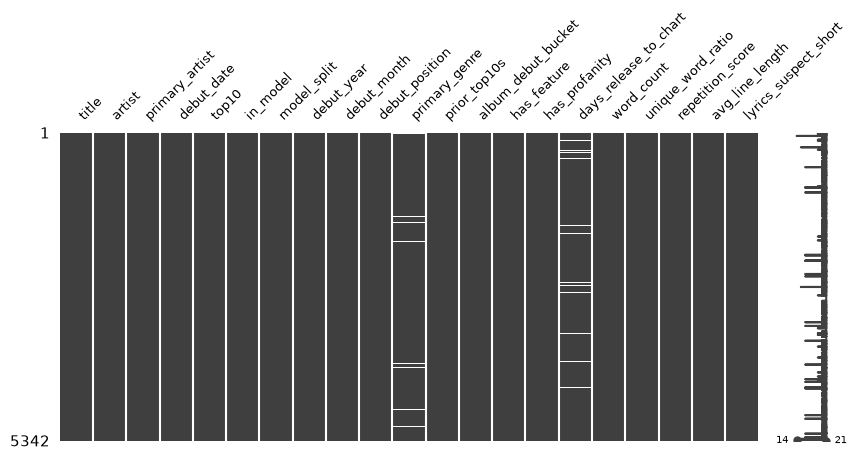

In [42]:
msno.matrix(songs, figsize=(10, 4), fontsize=9);

The Top 10 rate is steady at about one in ten across all nine years.

In [43]:
by_year = songs.groupby('debut_year').agg(songs=('title', 'size'), top10=('top10', 'sum'))
by_year['top10_rate'] = (by_year['top10'] / by_year['songs'] * 100).round(1)
by_year

,songs,top10,top10_rate
debut_year,,,
2018,595,67,11.3
2019,518,48,9.3
2020,674,65,9.6
2021,647,63,9.7
2022,629,77,12.2
2023,613,58,9.5
2024,617,63,10.2
2025,570,49,8.6
2026,479,29,6.1


### Summary: what we changed and why

| Column | Issue | Action | Justification |
|---|---|---|---|
| all | the archive has one row per song **per week** | Step 2: `groupby` + `agg` to one row per credit | we analyse songs, not weeks |
| `title`, `artist` | 34 songs were listed under two credits (e.g. "Kanye West" → "Ye") | Step 3: hand-checked rename list | their weeks were split and peaks understated; 5,377 → 5,342 songs, Top 10 521 → 519 |
| `artist` | one credit can name several artists | Step 4: replace separators, then `.str.split` | each artist's history must be counted |
| `artist` | three names contain a separator but are one act | Step 4: protected-names list | "Lil Nas X" would be cut by " x "; Sam & Dave and Sonny & Cher would leak into Dave's and Cher's histories |
| `prior_top10s` | history could include the song itself or later songs | Step 5: count only songs that debuted strictly earlier; two checks | otherwise the predictor would leak the answer |
| `top10` | 99 songs are still on the chart | Step 6: excluded from all tests | their peak is not final |
| `primary_genre` | hundreds of detailed labels | Step 8: keyword rules + vote counts | comparable broad groups |
| `primary_genre` | ties between genres | Step 8: artist's votes break ties, otherwise "mixed" | no arbitrary choice (e.g. alphabetical) |
| `duration` | 382 album-length or placeholder durations | Step 9: MusicBrainz length; 306 repaired | characters per second needs a real duration |
| lyrics | some uploads are cut short | Step 9: flag the slowest 2% per genre | used for the Q4 sensitivity check |
| lyrics | section tags such as `[Chorus]` | Step 10: removed with `.str.replace` | tags are not lyrics |
| lyric measures | 32 songs have no lyrics | Step 10: left blank, not 0 | a missing song is not a zero-word song |

Two problems were fixed earlier, when the collection scripts fetched the data, so the raw
files already include the fixes: LRCLIB sometimes returned an instrumental upload for a song
with vocals (we prefer a version with lyrics), and a search by title alone could return a
different artist's song of the same name (we require the artist to match).

**So what:** after cleaning there is one row per song, every predictor uses only what was known
at debut, and every remaining gap is explained.

## 4. Exploratory questions

Ten questions, each with a hypothesis, the numbers, a significance test, an interpretation
and a caveat. Five have a chart; the others use a summary table.

All tests use the **2018-2024 training songs**.

In [44]:
train = songs[songs['model_split'] == 'train'].copy()
test = songs[songs['model_split'] == 'test']
print('train (2018-2024):', len(train), 'songs,', train['top10'].sum(), 'Top 10')
print('test (2025-2026):', len(test), 'songs, held out')
print('overall Top 10 rate in train:', round(train['top10'].mean() * 100, 1), '%')

train (2018-2024): 4293 songs, 441 Top 10
test (2025-2026): 950 songs, held out
overall Top 10 rate in train: 10.3 %


**Two significance tests.** These are the only tools in this notebook that go beyond the
class material, so each is in one short helper:

- **Chi-square** asks whether the Top 10 rate differs between groups (e.g. genres).
  **Cramér's V** says how strong the link is: below 0.1 is negligible, 0.1-0.3 is small.
  With about 4,300 songs almost any difference is "significant", so V matters.
- **Mann-Whitney U** compares a number (e.g. word count) between Top 10 songs and the rest
  without assuming a bell curve.

We read a p-value below 0.05 as significant.

In [45]:
def chi_square_test(data, column, other_column='top10'):
    # Count the songs in each combination of the two columns, then test whether they are related.
    counts = pd.crosstab(data[column], data[other_column])
    chi2, p_value, dof, expected = stats.chi2_contingency(counts)
    # Cramer's V is the size of the link: 0 means none, 1 means perfect.
    cramers_v = np.sqrt(chi2 / (counts.values.sum() * (min(counts.shape) - 1)))
    print(f"chi-square = {chi2:.1f}, p = {p_value:.2e}, Cramer's V = {cramers_v:.3f}")
    return p_value, cramers_v

In [46]:
def mann_whitney_test(data, column):
    # Compare a number (e.g. word count) for Top 10 songs against all other songs.
    hits = data[data['top10'] == True][column].dropna()
    others = data[data['top10'] == False][column].dropna()
    u_stat, p_value = stats.mannwhitneyu(hits, others)
    print(f"{column}: median Top 10 = {hits.median():.3f}, median others = {others.median():.3f}, p = {p_value:.2e}")
    return hits.median(), others.median(), p_value

### Q1. Does genre relate to the chance of a Top 10 hit?

**Hypothesis.** H₀: the Top 10 rate is the same for every broad genre. H₁: it differs. We
expect pop to do better, since pop is made for broad radio appeal.

In [47]:
q1 = train.groupby('primary_genre').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q1['top10_rate'] = (q1['top10_rate'] * 100).round(1)
q1 = q1.sort_values('top10_rate', ascending=False)
q1_p, q1_v = chi_square_test(train, 'primary_genre')
q1

chi-square = 89.1, p = 7.09e-16, Cramer's V = 0.146


,songs,top10_rate
primary_genre,,
pop,796,18.7
dance/electronic,106,16.0
rock/alternative,94,13.8
R&B,321,9.3
hip-hop/rap,2017,8.8
other,97,8.2
mixed,46,6.5
Latin,189,5.8
country,510,5.3


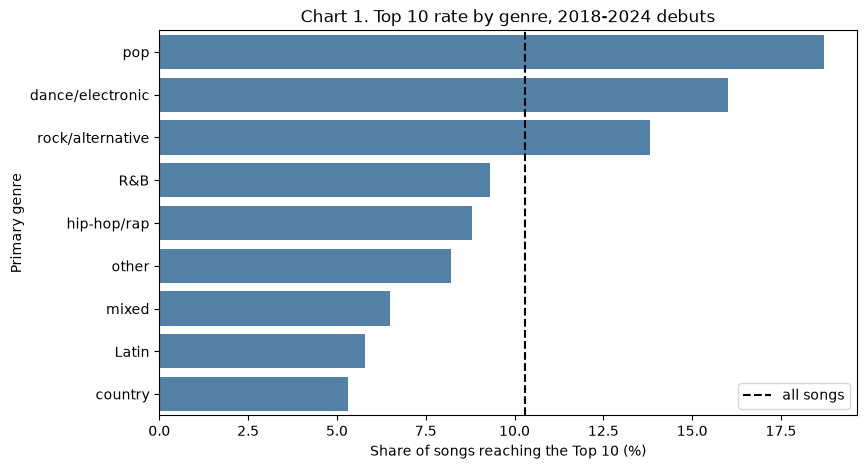

In [48]:
overall = round(train['top10'].mean() * 100, 1)

plt.figure(figsize=(9, 5))
sns.barplot(x='top10_rate', y='primary_genre', data=q1.reset_index(), color='steelblue')
plt.axvline(overall, color='k', linestyle='--', label='all songs')
plt.title('Chart 1. Top 10 rate by genre, 2018-2024 debuts')
plt.xlabel('Share of songs reaching the Top 10 (%)')
plt.ylabel('Primary genre')
plt.legend()
plt.show()

**In plain English:** pop songs reach the Top 10 about three and a half times as often as
country songs, but genre is only a modest factor.

**Interpretation.** Pop leads at **18.7%** and country trails at **5.3%**, and the test is
clear (p = 7.1×10⁻¹⁶). But Cramér's V is **0.146**, a *small* effect: genre shifts the
odds without deciding them. Hip-hop/rap is by far the largest genre (2,017 songs) yet
converts at only **8.8%**, below the 10.3% average.

**Caveat.** Genre comes from how MusicBrainz volunteers tagged each song. 166 songs have no
genre and are left out, and 71 are "mixed" because two genres tied. Recent songs are less
tagged, so 2026 has the lowest coverage.

### Q2. Does an artist's past success predict the next hit?

**Hypothesis.** H₀: the number of earlier Top 10 hits is unrelated to reaching the Top 10.
H₁: artists with more earlier hits are more likely to have another, through their fanbase,
playlists and label budget.

In [49]:
def prior_bucket(count):
    if count == 0:
        return '0'
    elif count <= 4:
        return '1-4'
    elif count <= 9:
        return '5-9'
    else:
        return '10+'

In [50]:
train['prior_bucket'] = train['prior_top10s'].apply(prior_bucket)
q2 = train.groupby('prior_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q2['top10_rate'] = (q2['top10_rate'] * 100).round(1)
q2 = q2.reindex(['0', '1-4', '5-9', '10+'])
q2_p, q2_v = chi_square_test(train, 'prior_bucket')
q2

chi-square = 107.7, p = 3.44e-23, Cramer's V = 0.158


,songs,top10_rate
prior_bucket,,
0,1472,5.8
1-4,1456,8.7
5-9,458,13.3
10+,907,18.5


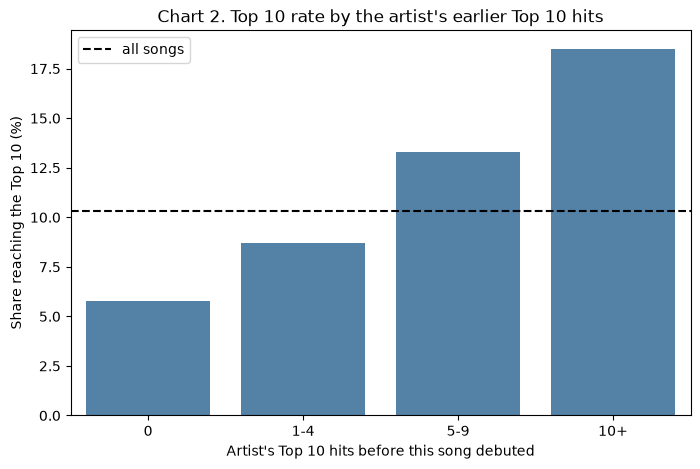

In [51]:
plt.figure(figsize=(8, 5))
sns.barplot(x='prior_bucket', y='top10_rate', data=q2.reset_index(), color='steelblue')
plt.axhline(overall, color='k', linestyle='--', label='all songs')
plt.title("Chart 2. Top 10 rate by the artist's earlier Top 10 hits")
plt.xlabel("Artist's Top 10 hits before this song debuted")
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend()
plt.show()

**In plain English:** the more hits an artist already has, the more likely the next song is
a hit: about 1 in 17 for newcomers, nearly 1 in 5 for stars.

**Interpretation.** The clearest pattern in the study, and it rises steadily: **5.8%** with
no earlier Top 10, **8.7%** at 1-4, **13.3%** at 5-9 and **18.5%** at 10 or more. An
artist with ten earlier hits is **3.2 times** as likely to land another as a newcomer
(p = 3.4×10⁻²³, V = 0.158, the largest effect we measure).

**Caveat.** This measures the artist, not the song, and it partly feeds itself: established
artists get the playlist placement and marketing that *cause* the next hit. It is a good
predictor and a weak explanation, and it says nothing about unknown artists, which is where a
prediction would be most useful.

### Q3. Does releasing many songs at once change a song's chances?

**Hypothesis.** H₀: the number of songs an artist debuts in the same week is unrelated to
the target. H₁: songs released together compete for the same listeners, so a big album
drop lowers each song's chance.

In [52]:
q3 = train.groupby('album_debut_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q3['top10_rate'] = (q3['top10_rate'] * 100).round(1)
q3 = q3.reindex(['1', '2-4', '5-9', '10+'])
q3_p, q3_v = chi_square_test(train, 'album_debut_bucket')
q3

chi-square = 44.5, p = 1.16e-09, Cramer's V = 0.102


,songs,top10_rate
album_debut_bucket,,
1,2123,11.6
2-4,366,6.3
5-9,425,2.1
10+,1379,11.8


The overall pattern is U-shaped: 11.6% alone, 2.1% at 5-9 songs, back to 11.8% at 10+. To
see whether the rise at 10+ comes from *who* releases big drops, we split artists into
newcomers and established artists (at least one earlier Top 10).

In [53]:
def artist_group(prior_top10s):
    if prior_top10s > 0:
        return 'Established (1+ earlier Top 10)'
    else:
        return 'Newcomer (no earlier Top 10)'

train['artist_group'] = train['prior_top10s'].apply(artist_group)
q3_split = train.groupby(['album_debut_bucket', 'artist_group']).agg(
    songs=('top10', 'size'), top10_rate=('top10', 'mean')).reset_index()
q3_split['top10_rate'] = (q3_split['top10_rate'] * 100).round(1)
q3_split

,album_debut_bucket,artist_group,songs,top10_rate
0,1,Established (1+ earlier Top 10),1011,17.0
1,1,Newcomer (no earlier Top 10),1112,6.7
2,10+,Established (1+ earlier Top 10),1248,12.7
3,10+,Newcomer (no earlier Top 10),131,3.1
4,2-4,Established (1+ earlier Top 10),247,7.3
5,2-4,Newcomer (no earlier Top 10),119,4.2
6,5-9,Established (1+ earlier Top 10),315,2.2
7,5-9,Newcomer (no earlier Top 10),110,1.8


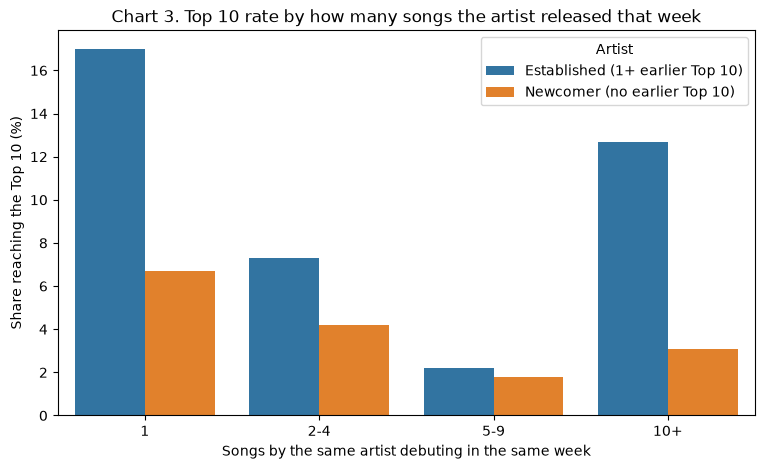

In [54]:
plt.figure(figsize=(9, 5))
sns.barplot(x='album_debut_bucket', y='top10_rate', hue='artist_group', data=q3_split,
            order=['1', '2-4', '5-9', '10+'])
plt.title('Chart 3. Top 10 rate by how many songs the artist released that week')
plt.xlabel('Songs by the same artist debuting in the same week')
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend(title='Artist')
plt.show()

**In plain English:** releasing many songs at once hurts each song's chances; huge drops of
10+ songs only look fine because they come from superstars.

**Interpretation.** Drop size matters (p = 1.2×10⁻⁹, V = 0.102), and the split shows two
stories behind the U-shape. For both groups, releasing more songs at once lowers each song's
odds: established artists fall from **17.0%** alone to **7.3%** in a 2-4 song drop and
**2.2%** at 5-9; newcomers follow the same path at a lower level, **6.7%**, **4.2%** and
**1.8%**. At 5-9 songs the gap between the two groups almost disappears.

The rise at ten or more happens only for established artists, who climb back to **12.7%**,
while newcomers stay at **3.1%**. So the pooled 11.8% at 10+ does not mean big drops work:
1,248 of those 1,379 songs come from established artists, whose songs chart well anyway.
Even for them, a 10+ drop does worse than a solo release (12.7% vs 17.0%).

**Caveat.** "At least one earlier Top 10" puts an artist with one hit in the same group as
Drake, and we have not held each artist fixed. Two newcomer bars rest on very few hits
(110 songs at 5-9, 131 at 10+), so those rates are suggestive, not firm.

### Q4. Do the lyrics of Top 10 songs differ measurably?

**Hypothesis.** H₀: the lyric measures look the same for both groups. H₁: hits are more
repetitive and use a smaller vocabulary, the "catchiness" idea.

In [55]:
lyric_measures = ['word_count', 'unique_word_ratio', 'repetition_score', 'avg_line_length']
q4_results = []
for measure in lyric_measures:
    q4_results.append(mann_whitney_test(train, measure))

word_count: median Top 10 = 433.000, median others = 422.000, p = 7.31e-02
unique_word_ratio: median Top 10 = 0.348, median others = 0.361, p = 9.51e-05
repetition_score: median Top 10 = 0.433, median others = 0.419, p = 1.69e-01
avg_line_length: median Top 10 = 7.847, median others = 7.865, p = 2.01e-01


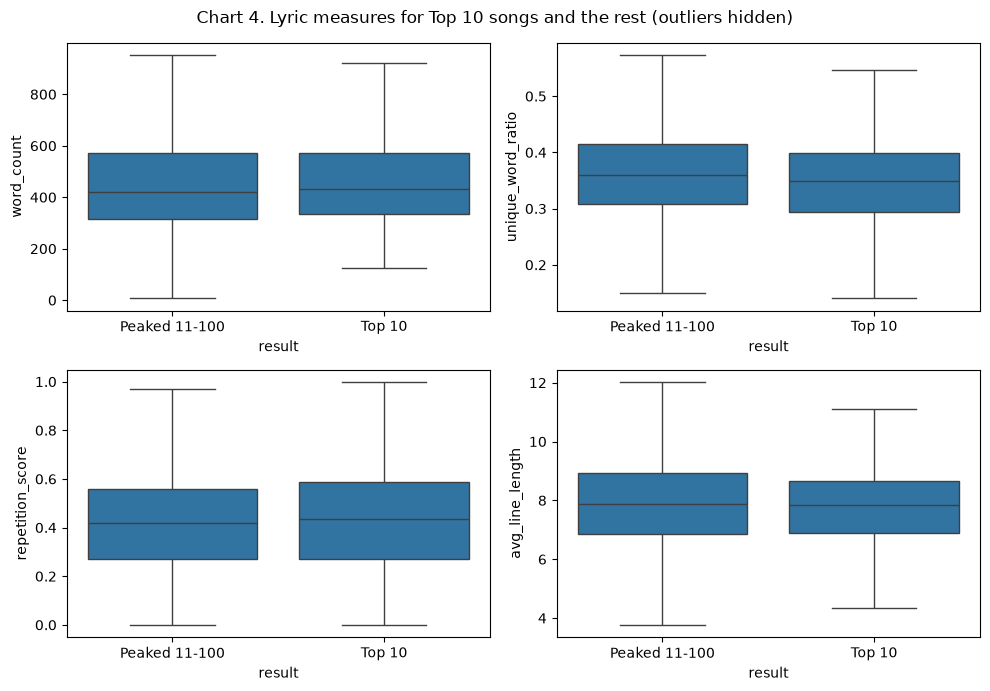

In [56]:
train['result'] = train['top10'].map({True: 'Top 10', False: 'Peaked 11-100'})

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
sns.boxplot(x='result', y='word_count', data=train, showfliers=False, ax=axes[0, 0])
sns.boxplot(x='result', y='unique_word_ratio', data=train, showfliers=False, ax=axes[0, 1])
sns.boxplot(x='result', y='repetition_score', data=train, showfliers=False, ax=axes[1, 0])
sns.boxplot(x='result', y='avg_line_length', data=train, showfliers=False, ax=axes[1, 1])
plt.suptitle('Chart 4. Lyric measures for Top 10 songs and the rest (outliers hidden)')
plt.tight_layout()
plt.show()

**Sensitivity check.** We repeat the tests without the songs whose lyrics may be cut short.

In [57]:
# Sensitivity check: leave out songs whose lyrics may be cut short, then test again.
complete = train[train['lyrics_suspect_short'] == False]
print('songs left out:', len(train) - len(complete))
for measure in lyric_measures:
    mann_whitney_test(complete, measure)

songs left out: 84
word_count: median Top 10 = 435.000, median others = 426.000, p = 1.61e-01
unique_word_ratio: median Top 10 = 0.348, median others = 0.360, p = 2.62e-04
repetition_score: median Top 10 = 0.432, median others = 0.418, p = 1.81e-01
avg_line_length: median Top 10 = 7.849, median others = 7.898, p = 1.22e-01


**In plain English:** on these four measures, hits and non-hits look almost the same.

**Interpretation.** Mostly a null result. Only **unique word ratio** differs significantly
(0.348 vs 0.361, p = 9.5×10⁻⁵): Top 10 songs use a slightly smaller vocabulary, which fits
the catchiness idea but is too small to act on. Word count (433 vs 422, p = 0.073),
repetition (0.433 vs 0.419, p = 0.169) and line length (7.85 vs 7.86, p = 0.201) show no
difference, and the boxes overlap almost completely. Leaving out the 84 songs whose lyrics
may be cut short gives the same answer: only unique word ratio is significant (p = 0.00026).

**Caveat.** These measure the *form* of the lyrics, not what they say: a song about
heartbreak and a song about money can score the same. The fair conclusion is that *these*
lyric features are weak, not that lyrics do not matter. 32 songs with no lyrics are left out.

### Q5. Is there a best month to release a hit?

**Hypothesis.** H₀: the debut month is unrelated to the target. H₁: some months are better,
as the industry's idea of spring and pre-holiday release slots suggests.

This also tests Q3: if big album drops change the odds and superstars choose when to release
them, a "month effect" may really be a release-schedule effect.

In [58]:
q5_all = train.groupby('debut_month').agg(top10_rate=('top10', 'mean'))
q5_all['top10_rate'] = (q5_all['top10_rate'] * 100).round(1)
print('All songs:')
q5_all_p, q5_all_v = chi_square_test(train, 'debut_month')

small_drops = train[train['album_debut_bucket'].isin(['1', '2-4'])]
q5_small = small_drops.groupby('debut_month').agg(top10_rate=('top10', 'mean'))
q5_small['top10_rate'] = (q5_small['top10_rate'] * 100).round(1)
print('Without drops of 5+ songs:')
q5_small_p, q5_small_v = chi_square_test(small_drops, 'debut_month')

pd.DataFrame({'all songs': q5_all['top10_rate'], 'without drops of 5+': q5_small['top10_rate']}).T

All songs:
chi-square = 25.0, p = 9.15e-03, Cramer's V = 0.076
Without drops of 5+ songs:
chi-square = 5.5, p = 9.06e-01, Cramer's V = 0.047


debut_month,1,2,3,4,5,6,7,8,9,10,11,12
all songs,9.0,8.7,7.0,10.8,15.1,9.7,8.7,9.4,9.7,9.9,14.8,9.6
without drops of 5+,10.3,9.8,8.9,11.3,14.3,11.9,9.3,11.5,9.2,12.0,11.5,9.7


The biggest same-artist release weeks in the training years:

In [59]:
# The biggest same-artist release weeks in the training years.
drop_weeks = train.groupby(['primary_artist', 'debut_date']).agg(
    songs=('top10', 'size'), top10=('top10', 'sum')).reset_index()
drop_weeks.sort_values('songs', ascending=False).head(8)

,primary_artist,debut_date,songs,top10
2121,taylor swift,2024-05-04,31,10
1603,morgan wallen,2023-03-18,27,1
2111,taylor swift,2021-11-27,26,1
1097,kanye west,2021-09-11,23,2
146,bad bunny,2022-05-21,22,4
1350,lil wayne,2018-10-13,22,4
2118,taylor swift,2023-07-22,22,1
592,drake,2023-10-21,22,6


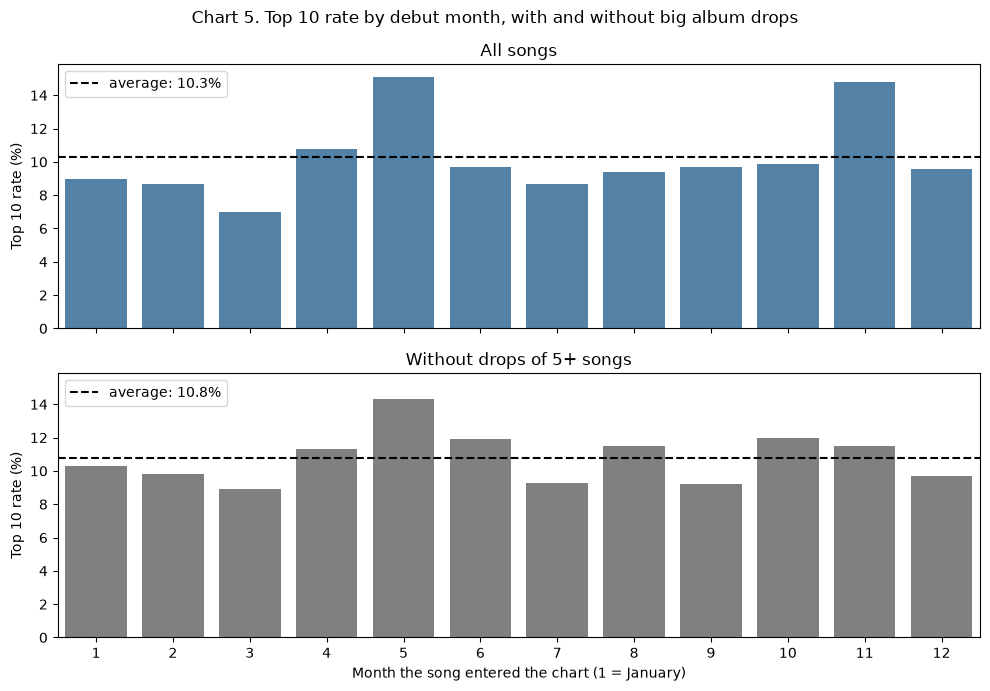

In [60]:
# Each panel gets its own average: the songs without big drops average 10.8%, not 10.3%.
small_average = round(small_drops['top10'].mean() * 100, 1)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)
sns.barplot(x='debut_month', y='top10_rate', data=q5_all.reset_index(), color='steelblue', ax=axes[0])
axes[0].axhline(overall, color='k', linestyle='--', label='average: ' + str(overall) + '%')
axes[0].set_title('All songs')
sns.barplot(x='debut_month', y='top10_rate', data=q5_small.reset_index(), color='gray', ax=axes[1])
axes[1].axhline(small_average, color='k', linestyle='--', label='average: ' + str(small_average) + '%')
axes[1].set_title('Without drops of 5+ songs')
for ax in axes:
    ax.set_ylabel('Top 10 rate (%)')
    ax.legend(loc='upper left')
axes[1].set_xlabel('Month the song entered the chart (1 = January)')
plt.suptitle('Chart 5. Top 10 rate by debut month, with and without big album drops')
plt.tight_layout()
plt.show()

**In plain English:** the "best months" mostly came from superstar album weeks; once those
are removed, no month stands out by more than chance.

**Interpretation.** Across all songs the month matters (p = 0.0092): May (**15.1%**) and
November (**14.8%**) stand well above the 10.3% average. Part of this is album drops: two of
the biggest release weeks in the training years were in May, Taylor Swift's on 2024-05-04
(31 songs, 10 in the Top 10) and Bad Bunny's on 2022-05-21 (22 songs, 4 in the Top 10).
Without drops of five or more songs the month test is no longer significant (p = 0.906,
V = 0.047). November falls to **11.5%**, close to the 10.8% average for these songs; May
stays higher at **14.3%** (27 of 189 songs).

**Caveat.** May's 14.3% is a single month picked out *after* looking at all twelve, which is
exactly what the overall test guards against, and that test finds no pattern. With 189
songs, a few hits more or less move May's rate by a couple of points.

### Q6. Do featured artists help?

**Hypothesis.** H₀: a "Featuring" credit is unrelated to the target. H₁: a featured artist
brings a second fanbase, so it should raise the chance. *(Table only.)*

In [61]:
q6 = train.groupby('has_feature').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q6['top10_rate'] = (q6['top10_rate'] * 100).round(1)
q6_p, q6_v = chi_square_test(train, 'has_feature')
q6

chi-square = 0.5, p = 4.94e-01, Cramer's V = 0.010


,songs,top10_rate
has_feature,,
False,3417,10.4
True,876,9.6


**In plain English:** having a featured artist makes no difference to the odds.

**Interpretation.** Songs with a featured artist reach the Top 10 at **9.6%**, against
**10.4%** without one (p = 0.494, V = 0.010). The idea that a guest verse buys reach is not
supported.

**Caveat.** `has_feature` only spots the word "Featuring" (or "feat."). A joint credit like
"Artist A & Artist B" is not counted as a feature, so some collaborations are in the
"no feature" group.

### Q7. Is explicit language linked to hits?

**Hypothesis.** H₀: profanity is unrelated to the target. H₁: explicit songs get less radio
play, which should lower their chance. *(Table only.)*

In [62]:
with_lyrics = train.dropna(subset=['has_profanity'])
q7 = with_lyrics.groupby('has_profanity').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q7['top10_rate'] = (q7['top10_rate'] * 100).round(1)
q7_p, q7_v = chi_square_test(with_lyrics, 'has_profanity')
q7

chi-square = 0.1, p = 7.36e-01, Cramer's V = 0.005


,songs,top10_rate
has_profanity,,
False,1978,10.5
True,2296,10.1


Profanity is much more common in some genres than others:

In [63]:
profanity_by_genre = with_lyrics.groupby('primary_genre')['has_profanity'].mean() * 100
profanity_by_genre.round(1).sort_values(ascending=False)

primary_genre
hip-hop/rap         85.7
R&B                 53.9
dance/electronic    36.8
mixed               32.6
rock/alternative    28.7
pop                 25.4
Latin                9.0
other                8.4
country              7.9
Name: has_profanity, dtype: object

**In plain English:** explicit lyrics make no difference to the odds.

**Interpretation.** **10.1%** for explicit songs against **10.5%** for clean ones
(p = 0.736, V = 0.005). The radio idea is not supported in the streaming era, which makes
sense: chart position now depends mostly on streams, where an explicit label costs nothing.

**Caveat.** The flag is a word list applied to transcribed lyrics, so censored spellings
can be missed. It is also close to a genre marker: 85.7% of hip-hop/rap songs are explicit,
so the flag adds little on its own.

### Q8. Do hits chart sooner after release?

**Hypothesis.** H₀: the time from release to chart debut is the same for both groups. H₁:
hits chart right away from release-week streaming, while other songs build slowly.
*(Table only.)*

In [64]:
q8_hits, q8_others, q8_p = mann_whitney_test(train, 'days_release_to_chart')
train.groupby('top10')['days_release_to_chart'].describe()

days_release_to_chart: median Top 10 = 15.000, median others = 15.000, p = 4.96e-05


,count,mean,std,min,25%,50%,75%,max
top10,,,,,,,,
False,3521.0,182.107640,956.260268,-2830.0,15.0,15.0,25.0,22362.0
True,377.0,140.931034,1120.589152,-1714.0,15.0,15.0,16.0,20119.0


**In plain English:** most songs chart about two weeks after release either way; songs that
take months to chart are the ones that rarely become hits.

**Interpretation.** Both groups have a median of **15 days**, yet the test is significant
(p = 5.0×10⁻⁵). Mann-Whitney compares whole distributions, not just medians: the groups match
at the middle and differ in the slow tail, where the 75th percentile is **25 days** for
non-hits but **16 days** for hits. A slow climb onto the chart is a non-hit pattern.

**Caveat.** Saying "medians are equal, p < 0.001" without this explanation would mislead.
The mean is not useful here (141 vs 182 days) because reissues give some songs release dates
decades before they charted. Songs with only a release year are left out.

### Q9. Has the genre mix of the Top 10 changed since 2018?

**Hypothesis.** H₀: the genre mix of Top 10 songs is stable from year to year. H₁: it has
changed. The project brief asks how hits changed over time. *(Table only.)*

In [65]:
hits = train[train['top10'] == True].dropna(subset=['primary_genre'])
q9_p, q9_v = chi_square_test(hits, 'debut_year', 'primary_genre')

q9 = pd.crosstab(hits['debut_year'], hits['primary_genre'], normalize='index') * 100
q9[['hip-hop/rap', 'pop', 'country', 'R&B']].round(1)

chi-square = 82.9, p = 1.31e-03, Cramer's V = 0.178


primary_genre,hip-hop/rap,pop,country,R&B
debut_year,,,,
2018,56.7,26.9,0.0,6.0
2019,27.7,53.2,2.1,4.3
2020,45.3,39.1,4.7,1.6
2021,42.6,27.9,3.3,16.4
2022,37.7,31.2,9.1,5.2
2023,35.1,29.8,12.3,3.5
2024,36.5,36.5,11.1,11.1


**In plain English:** between 2018 and 2024, hip-hop's share of Top 10 hits fell and
country's rose.

**Interpretation.** The mix has changed (p = 0.0013). Hip-hop/rap's share of Top 10 songs
fell from **56.7%** in 2018 to **36.5%** in 2024, while country rose from **0.0%** to
**11.1%**; country had no Top 10 song at all in our 2018 data. Pop moves around rather than
trending, between 26.9% and 53.2%.

**Caveat.** Each year has only about 50-70 Top 10 songs, so single years are noisy; the
direction over the whole period is more reliable than any one year.

### Q10. Does debut position predict the peak, or is the question circular?

**Hypothesis.** H₀: debut position is unrelated to reaching the Top 10. H₁: a strong debut
predicts a strong peak. We include this question because it is a trap. *(Table only.)*

In [66]:
def debut_bucket(position):
    if position <= 10:
        return '1-10'
    elif position <= 25:
        return '11-25'
    elif position <= 50:
        return '26-50'
    elif position <= 75:
        return '51-75'
    else:
        return '76-100'

In [67]:
train['debut_bucket'] = train['debut_position'].apply(debut_bucket)
q10_naive = train.groupby('debut_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q10_naive['top10_rate'] = (q10_naive['top10_rate'] * 100).round(1)
q10_naive

,songs,top10_rate
debut_bucket,,
1-10,303,100.0
11-25,435,6.7
26-50,775,4.8
51-75,1098,2.6
76-100,1682,2.6


Every song that debuted at 1-10 is a Top 10 song. That is not a finding: `top10` means the
song *ever* reached positions 1-10, so debuting there already meets the definition. The
honest question is about songs that debuted outside the Top 10:

In [68]:
outside = train[train['debut_position'] > 10]
print('songs that debuted inside the Top 10:', len(train) - len(outside))
q10 = outside.groupby('debut_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q10['top10_rate'] = (q10['top10_rate'] * 100).round(1)
q10_p, q10_v = chi_square_test(outside, 'debut_bucket')
q10

songs that debuted inside the Top 10: 303
chi-square = 23.7, p = 2.86e-05, Cramer's V = 0.077


,songs,top10_rate
debut_bucket,,
11-25,435,6.7
26-50,775,4.8
51-75,1098,2.6
76-100,1682,2.6


**In plain English:** debuting in the Top 10 makes a song a Top 10 song by definition, so we
only look at songs that climbed in; starting higher helps, but only a little.

**Interpretation.** The naive table shows a **100%** Top 10 rate for debuts at 1-10, which
looks like the strongest predictor in the study but is pure **target leakage**. Leaving out
those 303 songs gives the real answer: climbing into the Top 10 still depends on where a song
starts, from **6.7%** for debuts at 11-25 down to **2.6%** at 76-100 (p = 2.9×10⁻⁵), but the
effect is small (V = 0.077), much weaker than the artist's track record.

**Caveat.** A feature measured during the outcome must be checked against the *definition* of
the target, not just its timing. A predictor that looks too good deserves suspicion first.

**So what:** of ten hypotheses, four hold up (genre, artist history, release strategy, and
genre change over time), three are null results worth reporting (lyric style, featured
artists, profanity), and three only made sense once a confounder or a definition was pinned
down (the U-shape, the month effect, and debut position).

## 5. Conclusion

### 5.1 Prioritised insights

| # | Insight | Evidence | Impact | Feasibility | Verdict |
|---|---|---|---|---|---|
| 1 | **Release strategy is the biggest lever a label controls.** A song released alone reaches the Top 10 at 11.6%; in a 5-9 song drop, 2.1%. Even established artists drop from 17.0% to 2.2% | Q3, p = 1.2×10⁻⁹ | **High**, a five-fold swing | **High**, release timing is a decision | **Act on it:** release singles on their own rather than as part of a mid-sized album drop |
| 2 | **The artist's track record is the strongest predictor, but not something a label can change.** 18.5% at 10+ earlier hits vs 5.8% with none | Q2, V = 0.158 | **High**, best single predictor | **Low**, fixed for a given artist | **Use it for forecasting,** not as advice |
| 3 | **Genre shifts the odds about 3.5 times.** Pop 18.7%, country 5.3% | Q1, p = 7.1×10⁻¹⁶ | **Medium**, real but small (V = 0.146) | **Low**, an artist cannot switch genre | **Use it as a baseline adjustment** |
| 4 | **Lyric style carries almost no signal.** Only vocabulary diversity differs, 0.348 vs 0.361 | Q4, 3 of 4 tests not significant | **Medium**, a useful negative result | **High**, cheap to stop here | **Stop investing in surface lyric measures;** try sentiment or topic instead |
| 5 | **Two apparent effects were artefacts.** The month effect was mostly album schedules; debut position was target leakage | Q5, Q10 | **High**, both would have been wrong claims | **High**, one extra test each | **Re-test any effect that could come from who released the song** |

### 5.2 Risks and limitations

**Licensing.** The Billboard archive declares no licence and LRCLIB publishes none; only
MusicBrainz is CC0. This is non-commercial academic work, and the lyrics are not redistributed.

**Coverage.** 166 songs (3.1%) have no genre, and coverage is lowest for 2026 because recent
releases are less tagged. 55 songs have no MusicBrainz match, mostly titles such as
"B.I.T.C.H." or "1.5" that the search could not handle; missing data that depends on how a
title is written is not random.

**Measurement.** Genre comes from volunteer tags, not a fixed system; 71 songs are "mixed".
The profanity flag is a word list. 110 songs have lyrics that may be cut short.

**Design.** The target is a cut-off on a continuous outcome: a song peaking at 11 is grouped
with one peaking at 100. Seven training years are only seven points for any yearly trend.
Album-drop size is tangled with artist size. And everything here is **association, not
causation**: nothing was randomised.

### 5.3 Next steps

1. **Fit a baseline model** on the 2018-2024 songs (logistic regression with earlier Top 10s,
   genre and album-drop size) and evaluate it once on the 2025-2026 test set. Report precision
   and recall, not accuracy: a model that always says "no" is 90% accurate and useless.
2. **Test what the lyrics say, not just their form:** sentiment and topic features.
3. **Separate artist size from release strategy** by comparing songs by the same artist.
4. **Re-run the MusicBrainz pull for 2026 songs** later in the year, once more are tagged.
5. **Recover the 55 unmatched songs** by matching on ISRC codes instead of title text.

**So what:** the finding a label can act on is *how* a song is released; the strongest
predictor is *who* released it; and the lyric-style idea that started the project does not
hold up.

## 6. References

**Data sources**

1. Hollingshead, M. *Billboard Hot 100 archive*, JSON files for every Billboard Hot 100 chart,
   1958-2026. https://github.com/mhollingshead/billboard-hot-100 (accessed September 2026).
   No licence declared by the repository.
2. *LRCLIB*, open lyrics database and API. https://lrclib.net/docs (accessed September 2026).
   No licence stated on the public documentation page.
3. *MusicBrainz*, open music encyclopedia. https://musicbrainz.org/doc/MusicBrainz_API
   (accessed September 2026). Core data released under CC0;
   https://musicbrainz.org/doc/About/Data_License.

**Software**

4. McKinney, W. (2010). Data structures for statistical computing in Python. *pandas*.
5. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature* 585, 357-362.
6. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in
   Python. *Nature Methods* 17, 261-272.
7. Hunter, J. D. (2007). Matplotlib: a 2D graphics environment. *Computing in Science &
   Engineering* 9(3), 90-95.
8. Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source
   Software* 6(60), 3021.
9. Bilogur, A. (2018). Missingno: a missing data visualization suite. *Journal of Open Source
   Software* 3(22), 547.

**Methods**

10. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
11. Mann, H. B. & Whitney, D. R. (1947). On a test of whether one of two random variables is
    stochastically larger than the other. *Annals of Mathematical Statistics* 18(1), 50-60.

**Project code.** The scripts in `scripts/` collected the raw files from the APIs. All
cleaning and analysis is in this notebook.

**So what:** every number here comes from a listed source and the code in this notebook.

## 7. AI usage disclosure

Our team used Claude as the primary AI assistant for this project. Claude Code, in VS Code,
wrote the data collection scripts in `scripts/`, the cleaning and analysis code in this
notebook, and first drafts of the written interpretations. Claude (chat) helped us plan the
analysis and review our work. The team made the judgment calls, including which duplicate
songs to merge, which artist names to protect, how to group genres, which questions to ask
and how to read the results, and reviewed all of the code and text. We tested the code,
corrected errors, and revised the AI-drafted explanations to match our own interpretation of
the results. We then checked that our written interpretations and conclusions were consistent
with the outputs, tables and charts in this notebook.

**So what:** AI wrote much of the code and first drafts; the decisions and the final review were ours.